# E-Commerce Business Analysis

## Project Overview
This notebook analyses the Olist Brazilian E-Commerce dataset (2016–2018) to identify business trends and operational insights.

## Objectives
- Analyse monthly sales and order trends.
- Identify top-performing product categories.
- Evaluate delivery performance.
- Understand customer purchasing behaviour.

## Tools Used
Python, Pandas, SQLite, SQL and Matplotlib.

In [1]:
import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt

conn = sqlite3.connect("../olist_analytics.db")

print("Database connected successfully!")

Database connected successfully!


In [2]:
monthly_revenue = pd.read_sql_query("""
    SELECT
        strftime('%Y-%m', o.order_purchase_timestamp) AS month,
        COUNT(DISTINCT o.order_id) AS total_orders,
        ROUND(SUM(oi.price), 2) AS product_revenue,
        ROUND(SUM(oi.freight_value), 2) AS freight_revenue,
        ROUND(SUM(oi.price + oi.freight_value), 2) AS total_gmv
    FROM orders o
    JOIN order_items oi
        ON o.order_id = oi.order_id
    WHERE o.order_status = 'delivered'
    GROUP BY month
    ORDER BY month
""", conn)

monthly_revenue.head(10)

,month,total_orders,product_revenue,freight_revenue,total_gmv
0,2016-09,1,134.97,8.49,143.46
1,2016-10,265,40325.11,6165.55,46490.66
2,2016-12,1,10.90,8.72,19.62
3,2017-01,750,111798.36,15684.01,127482.37
4,2017-02,1653,234223.40,37015.92,271239.32
5,2017-03,2546,359198.85,55132.10,414330.95
6,2017-04,2303,340669.68,50142.72,390812.40
7,2017-05,3546,489338.25,77513.15,566851.40
8,2017-06,3135,421923.37,68127.00,490050.37
9,2017-07,3872,481604.52,84694.56,566299.08


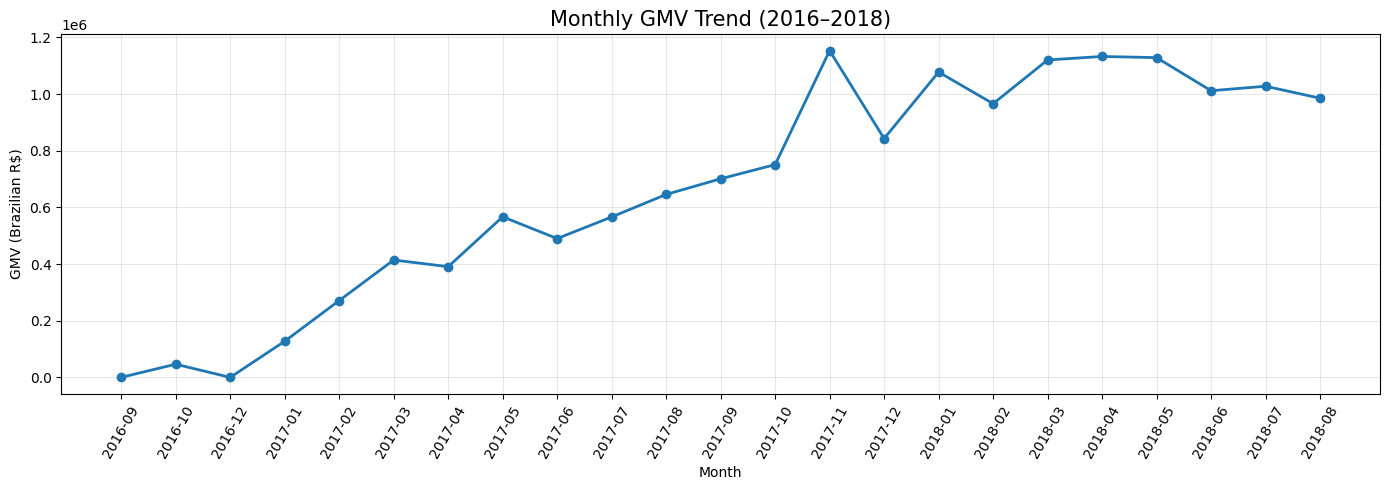

In [3]:
plt.figure(figsize=(14, 5))

plt.plot(
    monthly_revenue["month"],
    monthly_revenue["total_gmv"],
    marker="o",
    linewidth=2
)

plt.title("Monthly GMV Trend (2016–2018)", fontsize=15)
plt.xlabel("Month")
plt.ylabel("GMV (Brazilian R$)")
plt.xticks(rotation=60)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 1. Monthly Sales Analysis

This section analyses monthly e-commerce sales and order trends using delivered orders from the Olist dataset.

The analysis focuses on:

- Monthly order volume
- Product sales
- Freight revenue
- Total Gross Merchandise Value (GMV)

GMV is calculated as the sum of product prices and freight charges for delivered orders. It does not represent company profit or net revenue.

The objective is to understand sales growth patterns and identify changes in business activity over time.


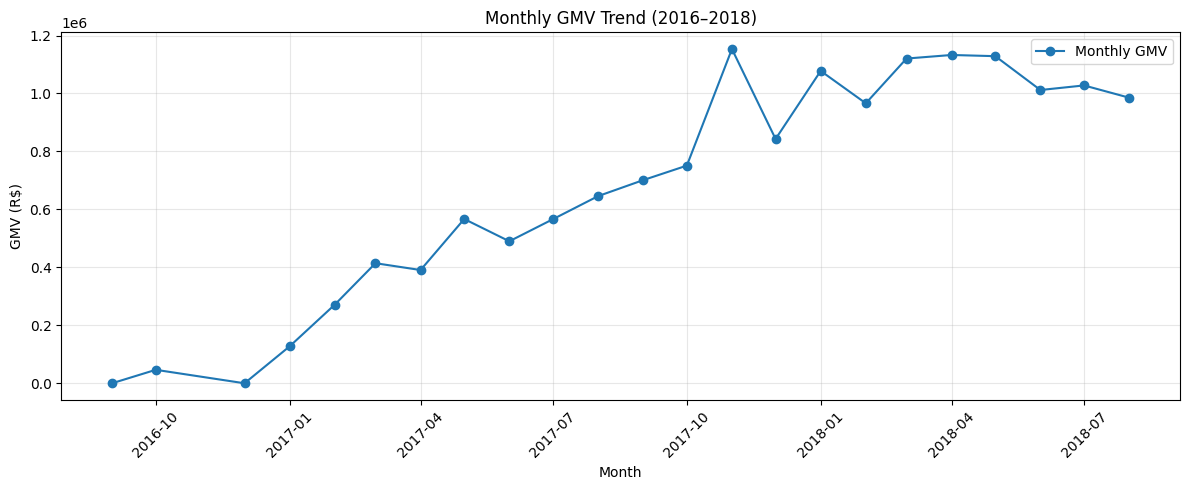

In [4]:

import matplotlib.pyplot as plt

monthly_revenue["month"] = pd.to_datetime(
    monthly_revenue["month"],
    format="%Y-%m"
)

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_revenue["month"],
    monthly_revenue["total_gmv"],
    marker="o",
    label="Monthly GMV"
)

plt.title("Monthly GMV Trend (2016–2018)")
plt.xlabel("Month")
plt.ylabel("GMV (R$)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [5]:

monthly_revenue[[
    "month",
    "total_orders",
    "product_revenue",
    "freight_revenue",
    "total_gmv"
]].tail(10)


,month,total_orders,product_revenue,freight_revenue,total_gmv
13,2017-11-01,7289,987765.37,165598.83,1153364.20
14,2017-12-01,5513,726033.19,117045.10,843078.29
15,2018-01-01,7069,924645.00,153242.46,1077887.46
16,2018-02-01,6555,826437.13,139731.28,966168.41
17,2018-03-01,7003,953356.25,167241.99,1120598.24
18,2018-04-01,6798,973534.09,159344.84,1132878.93
19,2018-05-01,6749,977544.69,151229.83,1128774.52
20,2018-06-01,6099,856077.86,155900.43,1011978.29
21,2018-07-01,6159,867953.46,159853.82,1027807.28
22,2018-08-01,6351,838576.64,146915.00,985491.64



### Business Interpretation

1. Monthly GMV increased significantly during 2017, indicating growth in transaction value.

2. November 2017 recorded the highest GMV of approximately R$ 1.15 million and the highest order volume of 7,289 orders.

3. Monthly GMV remained relatively strong throughout the first eight months of 2018.

4. Product sales contributed the major share of GMV, while freight charges added to the overall transaction value.

### Key Takeaway

The historical data shows substantial growth in e-commerce activity during 2017, followed by relatively stable monthly transaction values in 2018.


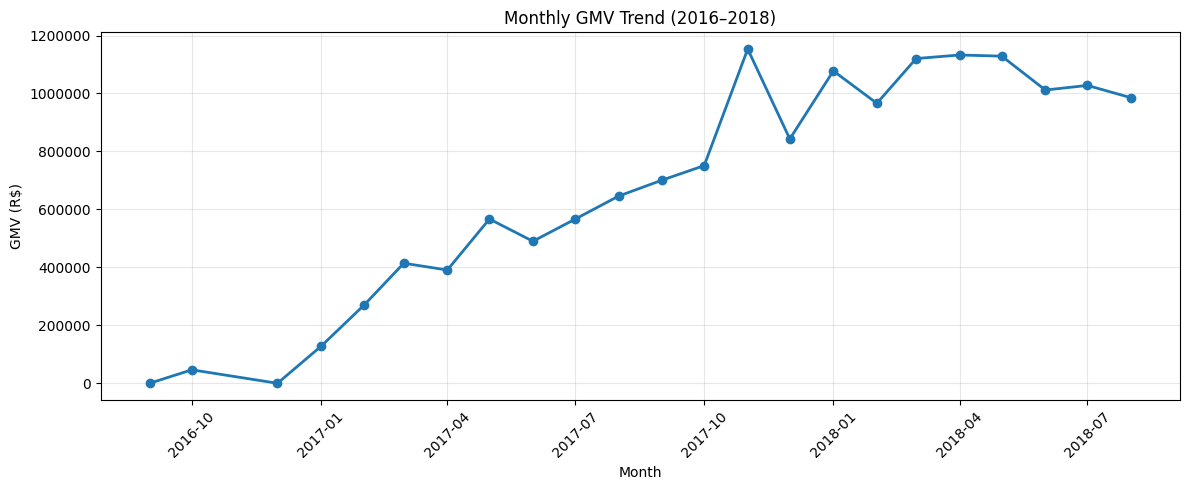

Minimum monthly GMV: 19.62
Maximum monthly GMV: 1153364.2


In [6]:

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_revenue["month"],
    monthly_revenue["total_gmv"],
    marker="o",
    linewidth=2
)

plt.title("Monthly GMV Trend (2016–2018)")
plt.xlabel("Month")
plt.ylabel("GMV (R$)")
plt.ticklabel_format(axis="y", style="plain")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Minimum monthly GMV:", monthly_revenue["total_gmv"].min())
print("Maximum monthly GMV:", monthly_revenue["total_gmv"].max())



## 2. Product Category Performance

This section evaluates the sales performance of different product categories using delivered orders.

The analysis focuses on:

- Total product sales generated by each category.
- Number of orders across categories.
- Average item price.
- Identification of the highest-performing categories.

The objective is to understand which product categories contribute most to overall sales and identify important business opportunities.


In [7]:

category_analysis = pd.read_sql_query("""
    SELECT
        COALESCE(
            ct.product_category_name_english,
            p.product_category_name,
            'Unknown'
        ) AS category,

        COUNT(DISTINCT oi.order_id) AS total_orders,
        ROUND(SUM(oi.price), 2) AS product_sales,
        ROUND(AVG(oi.price), 2) AS average_item_price,
        ROUND(SUM(oi.freight_value), 2) AS freight_revenue

    FROM order_items oi

    JOIN orders o
        ON oi.order_id = o.order_id

    JOIN products p
        ON oi.product_id = p.product_id

    LEFT JOIN category_translation ct
        ON p.product_category_name = ct.product_category_name

    WHERE o.order_status = 'delivered'

    GROUP BY category
    ORDER BY product_sales DESC
""", conn)

category_analysis.head(15)


,category,total_orders,product_sales,average_item_price,freight_revenue
0,health_beauty,8647,1233131.72,130.28,178957.81
1,watches_gifts,5495,1166176.98,199.04,98156.14
2,bed_bath_table,9272,1023434.76,93.44,201774.50
3,sports_leisure,7530,954852.55,113.25,163404.36
4,computers_accessories,6530,888724.61,116.26,143999.16
5,furniture_decor,6307,711927.69,87.25,168402.23
6,housewares,5743,615628.69,90.60,142763.56
7,cool_stuff,3559,610204.10,164.12,81476.79
8,auto,3810,578966.65,139.85,90488.10
9,toys,3804,471286.48,116.94,75774.58


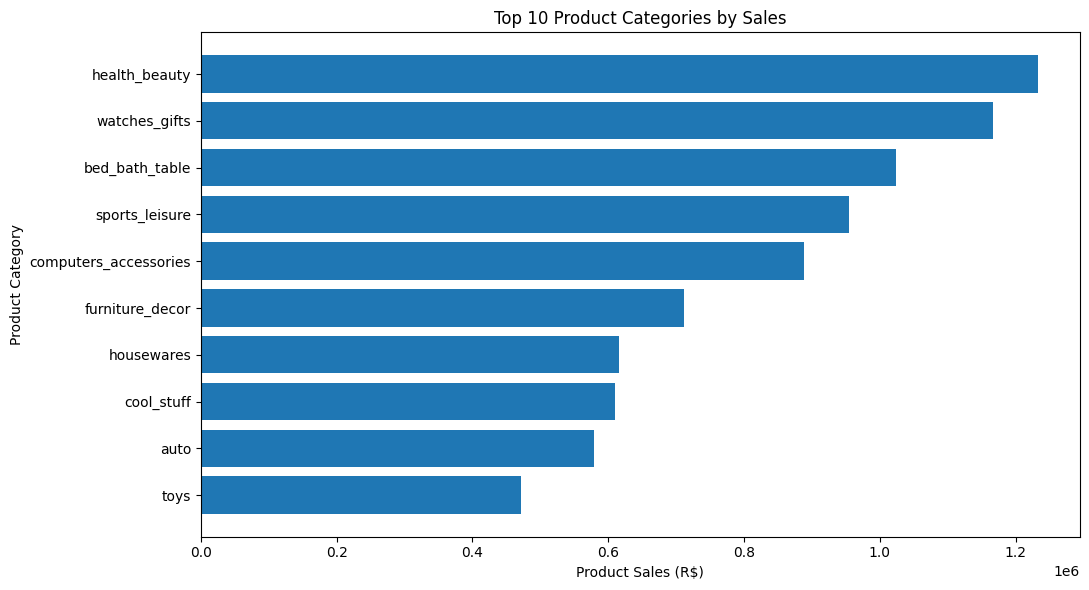

In [8]:

top_categories = category_analysis.head(10).sort_values(
    "product_sales"
)

plt.figure(figsize=(11, 6))

plt.barh(
    top_categories["category"],
    top_categories["product_sales"]
)

plt.title("Top 10 Product Categories by Sales")
plt.xlabel("Product Sales (R$)")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()



### Business Interpretation

1. Health & Beauty is the highest-performing category, generating approximately R$1.23 million in product sales.

2. Watches & Gifts ranks second, with sales of approximately R$1.16 million.

3. Bed, Bath & Table generates approximately R$1.02 million and has a strong contribution to overall sales.

4. Toys records the lowest sales among the top 10 categories.

### Key Takeaway

Health & Beauty, Watches & Gifts, and Bed, Bath & Table are the leading product categories by sales. These categories represent important opportunities for inventory planning and targeted marketing.

The analysis is based on delivered orders and product sales, not company profit.


In [10]:
category_orders = category_analysis[
    ["category", "total_orders", "average_item_price"]
].head(10)

category_orders

,category,total_orders,average_item_price
0,health_beauty,8647,130.28
1,watches_gifts,5495,199.04
2,bed_bath_table,9272,93.44
3,sports_leisure,7530,113.25
4,computers_accessories,6530,116.26
5,furniture_decor,6307,87.25
6,housewares,5743,90.60
7,cool_stuff,3559,164.12
8,auto,3810,139.85
9,toys,3804,116.94



### Order Volume and Pricing Insights

1. Bed, Bath & Table has the highest order volume, with 9,272 orders, despite ranking third in total sales.

2. Health & Beauty leads in total product sales, with 8,647 orders.

3. Watches & Gifts has the highest average item price among the top 10 categories, at approximately R$199.04.

4. Furniture Decor has the lowest average item price, at approximately R$87.25.

### Business Implications

- High-volume categories require efficient inventory and order fulfilment planning.
- High-value categories may benefit from targeted promotions and premium product positioning.
- Sales volume and average item price should be considered together when evaluating category performance.



## 3. Customer Behaviour and Retention Analysis

This section examines customer purchasing patterns using the Olist dataset.

The analysis focuses on:

- One-time versus repeat customers.
- Repeat purchase rate.
- Average customer spending.
- Revenue contribution by customer segment.

The objective is to understand customer retention patterns and identify opportunities to improve repeat purchases and long-term customer value.


In [11]:

customer_value = pd.read_sql_query("""
    WITH customer_orders AS (
        SELECT
            c.customer_unique_id,
            o.order_id,
            SUM(oi.price + oi.freight_value) AS order_value
        FROM orders o
        JOIN customers c
            ON o.customer_id = c.customer_id
        JOIN order_items oi
            ON o.order_id = oi.order_id
        WHERE o.order_status = 'delivered'
        GROUP BY c.customer_unique_id, o.order_id
    )

    SELECT
        customer_unique_id,
        COUNT(DISTINCT order_id) AS total_orders,
        ROUND(SUM(order_value), 2) AS total_spend,
        ROUND(AVG(order_value), 2) AS average_order_value
    FROM customer_orders
    GROUP BY customer_unique_id
""", conn)

customer_value["customer_type"] = customer_value[
    "total_orders"
].apply(
    lambda x: "Repeat Customer" if x > 1 else "One-time Customer"
)

customer_value.head()


,customer_unique_id,total_orders,total_spend,average_order_value,customer_type
0,0000366f3b9a7992bf8c76cfdf3221e2,1,141.90,141.90,One-time Customer
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,27.19,27.19,One-time Customer
2,0000f46a3911fa3c0805444483337064,1,86.22,86.22,One-time Customer
3,0000f6ccb0745a6a4b88665a16c9f078,1,43.62,43.62,One-time Customer
4,0004aac84e0df4da2b147fca70cf8255,1,196.89,196.89,One-time Customer


In [12]:

customer_summary = customer_value.groupby("customer_type").agg(
    total_customers=("customer_unique_id", "count"),
    average_spend=("total_spend", "mean"),
    total_revenue=("total_spend", "sum")
).round(2).reset_index()

customer_summary["customer_percentage"] = (
    customer_summary["total_customers"] /
    customer_summary["total_customers"].sum() * 100
).round(2)

customer_summary["revenue_percentage"] = (
    customer_summary["total_revenue"] /
    customer_summary["total_revenue"].sum() * 100
).round(2)

customer_summary


,customer_type,total_customers,average_spend,total_revenue,customer_percentage,revenue_percentage
0,One-time Customer,90557,160.73,14555586.29,97.0,94.4
1,Repeat Customer,2801,308.53,864187.46,3.0,5.6


In [13]:

repeat_customers = customer_value[
    customer_value["total_orders"] > 1
]["customer_unique_id"].nunique()

total_customers = customer_value["customer_unique_id"].nunique()

repeat_rate = repeat_customers / total_customers * 100

print("Total Unique Customers:", total_customers)
print("Repeat Customers:", repeat_customers)
print(f"Repeat Purchase Rate: {repeat_rate:.2f}%")


Total Unique Customers: 93358
Repeat Customers: 2801
Repeat Purchase Rate: 3.00%


## Customer Segmentation Analysis

This section compares one-time and repeat customers based on customer count, average spending and revenue contribution.

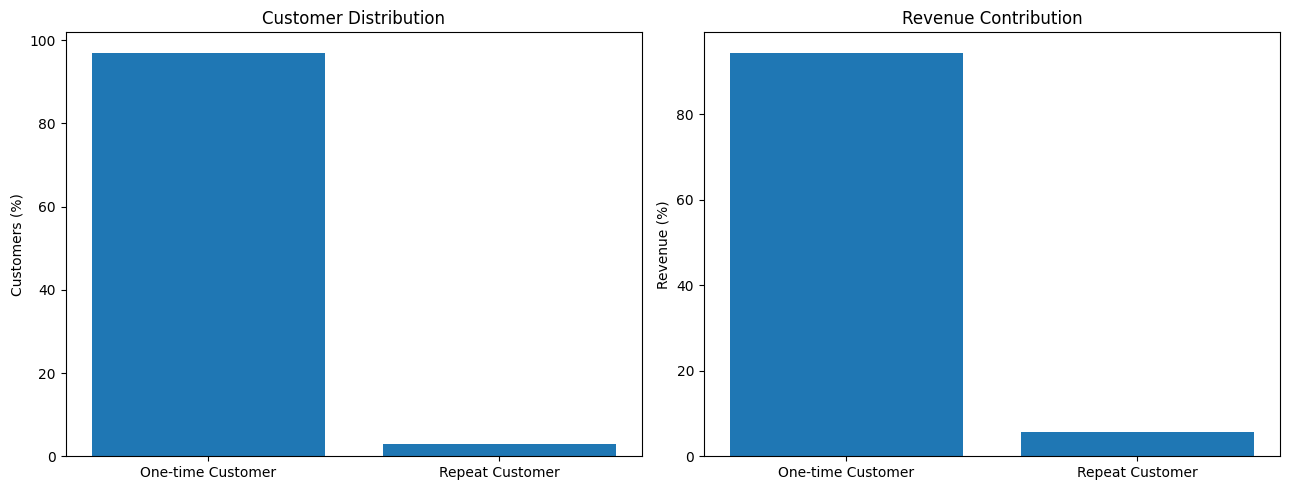

In [14]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].bar(
    customer_summary["customer_type"],
    customer_summary["customer_percentage"]
)
axes[0].set_title("Customer Distribution")
axes[0].set_ylabel("Customers (%)")

axes[1].bar(
    customer_summary["customer_type"],
    customer_summary["revenue_percentage"]
)
axes[1].set_title("Revenue Contribution")
axes[1].set_ylabel("Revenue (%)")

plt.tight_layout()
plt.show()


### Key Business Insights

1. One-time customers account for 97% of the customer base.
2. Repeat customers contribute 5.6% of total revenue despite representing only 3% of customers.
3. Average spending by repeat customers is approximately 1.92 times higher than one-time customers.
4. Improving customer retention and encouraging repeat purchases could create opportunities for revenue growth.

### Business Recommendation

Introduce targeted retention campaigns, personalised product recommendations and post-purchase engagement strategies to encourage second purchases.

## Delivery Performance Analysis

This section evaluates delivery timelines by comparing actual delivery dates with estimated delivery dates. It also examines how delivery delays relate to customer review scores.

In [15]:

delivery_analysis = pd.read_sql_query("""
    SELECT
        o.order_id,
        o.order_purchase_timestamp,
        o.order_delivered_customer_date,
        o.order_estimated_delivery_date,
        r.review_score
    FROM orders o
    LEFT JOIN (
        SELECT order_id, AVG(review_score) AS review_score
        FROM reviews
        GROUP BY order_id
    ) r ON o.order_id = r.order_id
    WHERE o.order_status = 'delivered'
      AND o.order_delivered_customer_date IS NOT NULL
      AND o.order_estimated_delivery_date IS NOT NULL
""", conn)

date_columns = [
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    delivery_analysis[col] = pd.to_datetime(
        delivery_analysis[col], errors="coerce"
    )

delivery_analysis["actual_delivery_days"] = (
    delivery_analysis["order_delivered_customer_date"] -
    delivery_analysis["order_purchase_timestamp"]
).dt.total_seconds() / 86400

delivery_analysis["delay_days"] = (
    delivery_analysis["order_delivered_customer_date"] -
    delivery_analysis["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

delivery_analysis["delivery_status"] = delivery_analysis[
    "delay_days"
].apply(lambda x: "Late" if x > 0 else "On Time")

delivery_summary = delivery_analysis.groupby(
    "delivery_status"
).agg(
    total_orders=("order_id", "count"),
    average_delivery_days=("actual_delivery_days", "mean"),
    average_review_score=("review_score", "mean")
).round(2).reset_index()

delivery_summary


,delivery_status,total_orders,average_delivery_days,average_review_score
0,Late,7826,31.52,2.57
1,On Time,88644,10.88,4.29


## Delivery Performance Visualization

This section compares late and on-time deliveries based on order volume, delivery duration and customer satisfaction.

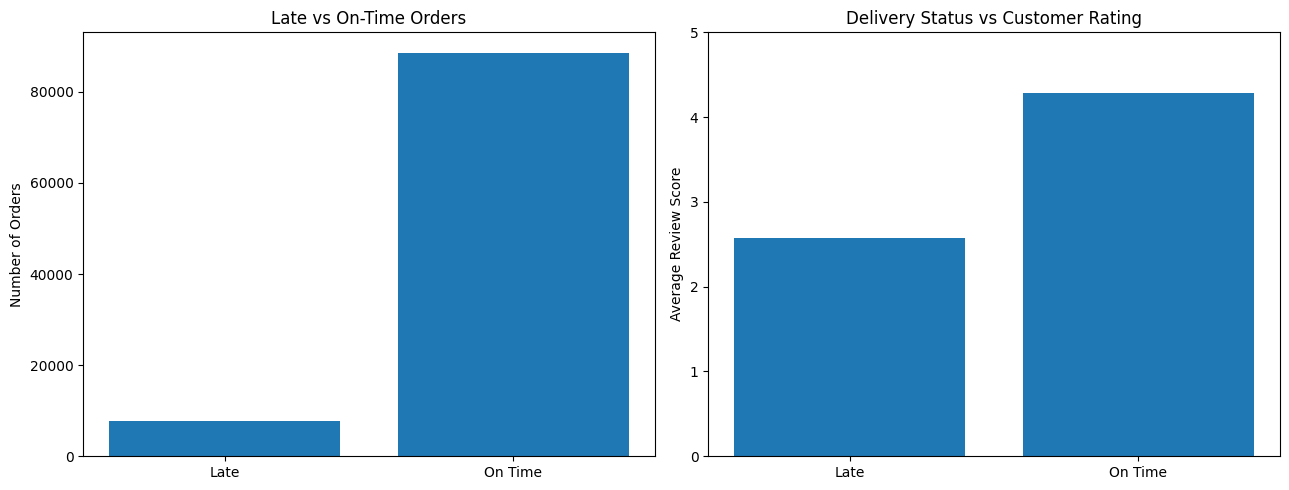

In [16]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].bar(
    delivery_summary["delivery_status"],
    delivery_summary["total_orders"]
)
axes[0].set_title("Late vs On-Time Orders")
axes[0].set_ylabel("Number of Orders")

axes[1].bar(
    delivery_summary["delivery_status"],
    delivery_summary["average_review_score"]
)
axes[1].set_title("Delivery Status vs Customer Rating")
axes[1].set_ylabel("Average Review Score")
axes[1].set_ylim(0, 5)

plt.tight_layout()
plt.show()


### Key Business Insights

1. Approximately 8.11% of analysed delivered orders arrived after the estimated delivery date.
2. Late deliveries took an average of 31.52 days, compared with 10.88 days for on-time deliveries.
3. Late deliveries received an average review score of 2.57, compared with 4.29 for on-time deliveries.

### Business Recommendations

- Improve delivery time estimation.
- Monitor sellers and logistics partners with frequent delays.
- Identify high-risk orders and take corrective action early.
- Improve customer communication when delays occur.

These findings show an association between delivery delays and lower customer ratings; they do not establish causation.

## Overall Business Summary

This analysis evaluates the Olist e-commerce dataset across sales performance, product categories, customer behaviour and delivery operations.

### Major Findings

1. Repeat customers represent approximately 3% of delivered-order customers but contribute 5.6% of total revenue.
2. Repeat customers spend approximately 1.92 times more on average than one-time customers.
3. Health & Beauty is the leading product category by sales.
4. Approximately 8.11% of analysed delivered orders arrived late.
5. Late deliveries are associated with lower average customer review scores.

### Strategic Recommendations

- Improve customer retention through targeted campaigns and personalised recommendations.
- Focus inventory planning on high-performing product categories.
- Monitor delivery delays and improve logistics coordination.
- Track repeat purchase rate, average order value and delivery performance as key business KPIs.

### Conclusion

The analysis highlights opportunities to improve customer retention, product performance and operational efficiency. These insights can support data-driven business decisions.

**Note:** The findings are based on historical Olist public dataset records from 2016–2018 and should not be interpreted as current business performance.